**Programming Assignment 1: Data Preparation and Understanding**

Image Dataset: Vehicle Type Recognition

Classes: Bus, Car, Truck, Motorcycle

Course: Data Minning 1

Instructor: Dr. Shen-Shyang Ho

Student Name: Jyoti Rani

Banner Id: 916592545

In [1]:
# Import required Libraries
import numpy as np
import matplotlib.pyplot as plt

from skimage import io, color, filters, exposure

In [2]:
# Upload the image dataset
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive.zip


In [3]:
# Extract the vehicle image dataset
import zipfile
zip_path = list(uploaded.keys())[0]
extract_path = '/content/archive'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
  zip_ref.extractall(extract_path)

print("Dataset extracted successfully")

Dataset extracted successfully


In [4]:
# Check extracted dataset folders
import os
os.listdir('/content/archive')

['Dataset']

**Section 2: Feature Extraction- Edge Histogram and Similarity Measurement**

**2(a):** Select One Image From Each Class

In [10]:
# Select one image from each vehicle class
dataset_path = '/content/archive/Dataset'

classes = ['Bus', 'Car', 'motorcycle', 'Truck']

for class_name in classes:
  folder_path = os.path.join(dataset_path, class_name)
  images = os.listdir(folder_path)

  print(class_name, ":", images[0])

Bus : Image_81.jpg
Car : Image_24.jpg
motorcycle : Image_24.jpg
Truck : Image_24.jpg


**2(b):** Convert Color Images to Grayscale

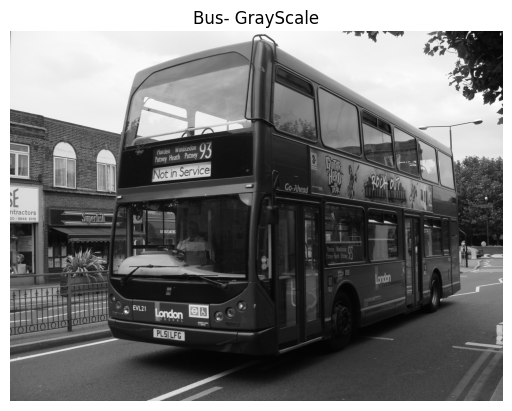

In [11]:
# Load Bus Image and Convert it to grayscale
bus_path = os.path.join(dataset_path, 'Bus', 'Image_42.jpg')
bus_image = io.imread(bus_path)
bus_gray = color.rgb2gray(bus_image)

plt.imshow(bus_gray, cmap='gray')
plt.title('Bus- GrayScale')
plt.axis('off')
plt.show()

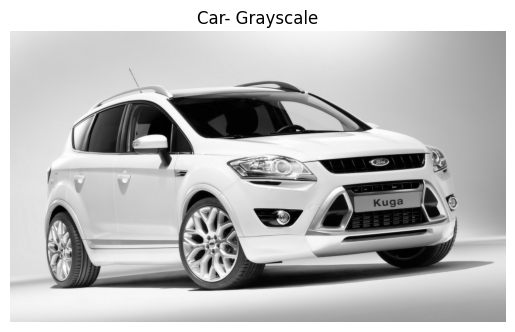

In [12]:
# Load Car image and convert it to grayscale
car_path = os.path.join(dataset_path, 'Car', 'Image_42.jpg')
car_image = io.imread(car_path)
car_gray = color.rgb2gray(car_image)

plt.imshow(car_gray, cmap='gray')
plt.title('Car- Grayscale')
plt.axis('off')
plt.show()

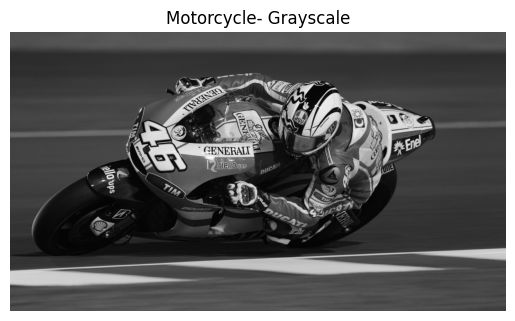

In [13]:
# Load Motorcycle image and convert it to grayscale
motorcycle_path = os.path.join(dataset_path, 'motorcycle', 'Image_42.jpg')
motorcycle_image = io.imread(motorcycle_path)
motorcycle_gray = color.rgb2gray(motorcycle_image)

plt.imshow(motorcycle_gray, cmap='gray')
plt.title('Motorcycle- Grayscale')
plt.axis('off')
plt.show()

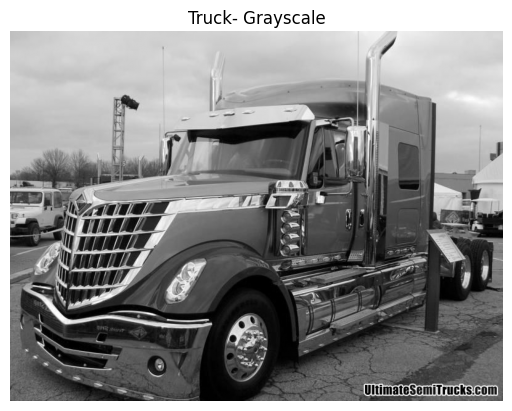

In [14]:
# Load Truck Image and Convert into grayscale
truck_path = os.path.join(dataset_path, 'Truck', 'Image_20.jpg')
truck_image = io.imread(truck_path)
truck_gray = color.rgb2gray(truck_image)

plt.imshow(truck_gray, cmap='gray')
plt.title('Truck- Grayscale')
plt.axis('off')
plt.show()


**2(c):** Calculate Edge Gradient Angels Using Sobel Filters

In [15]:
# Calculate edge gradient angles
def angle(dx, dy):
  """Calculate the angels between horizontal and vertical operators."""
  return np.mod(np.arctan2(dy, dx), np.pi)

# Calculate edge gradient angles for Bus
angle_bus = angle(filters.sobel_h(bus_gray), filters.sobel_v(bus_gray))

In [16]:
# Calculate edge gradient angles for Car
angle_car = angle(filters.sobel_h(car_gray), filters.sobel_v(car_gray))


In [17]:
# Calculate edge gradient angles for Motorcycle
angle_motorcycle = angle(filters.sobel_h(motorcycle_gray), filters.sobel_v(motorcycle_gray))

In [18]:
# Calculate edge gradient angles for Truck
angle_truck = angle(filters.sobel_h(truck_gray), filters.sobel_v(truck_gray))

**2(d):** Create 36-Bin Edge Histograms

In [19]:
# Create 36-bin histograms for Bus
hist_bus, bins_bus = exposure.histogram(angle_bus, nbins=36)

**2(e):** Plot Edge Histogram

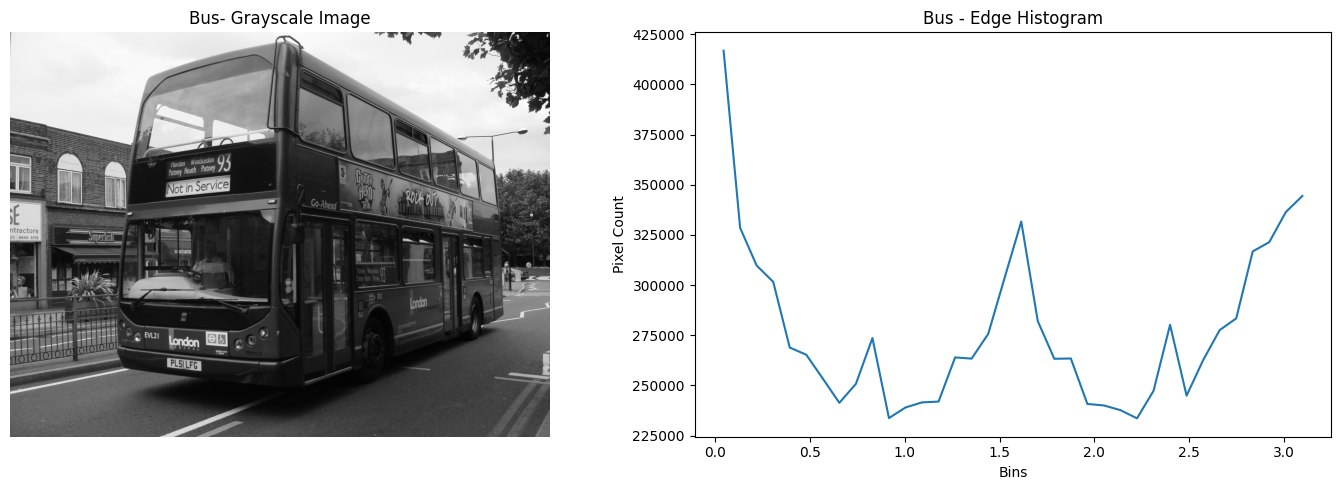

In [20]:
from IPython.core.pylabtools import figsize
# Create 36-bin edge histogram for Bus
hist_bus, bins_bus = exposure.histogram(angle_bus, nbins=36)

# Plot Bus image and its corresponding edge histogram
fig, ax = plt.subplots(1,2, figsize=(14, 5))
# Bus grayscale image
ax[0].imshow(bus_gray, cmap='gray')
ax[0].set_title("Bus- Grayscale Image")
ax[0].axis("off")

# Bus Edge Histogram
ax[1].plot(bins_bus, hist_bus)
ax[1].set_xlabel("Bins")
ax[1].set_ylabel("Pixel Count")
ax[1].set_title("Bus - Edge Histogram")
plt.tight_layout()
plt.show()


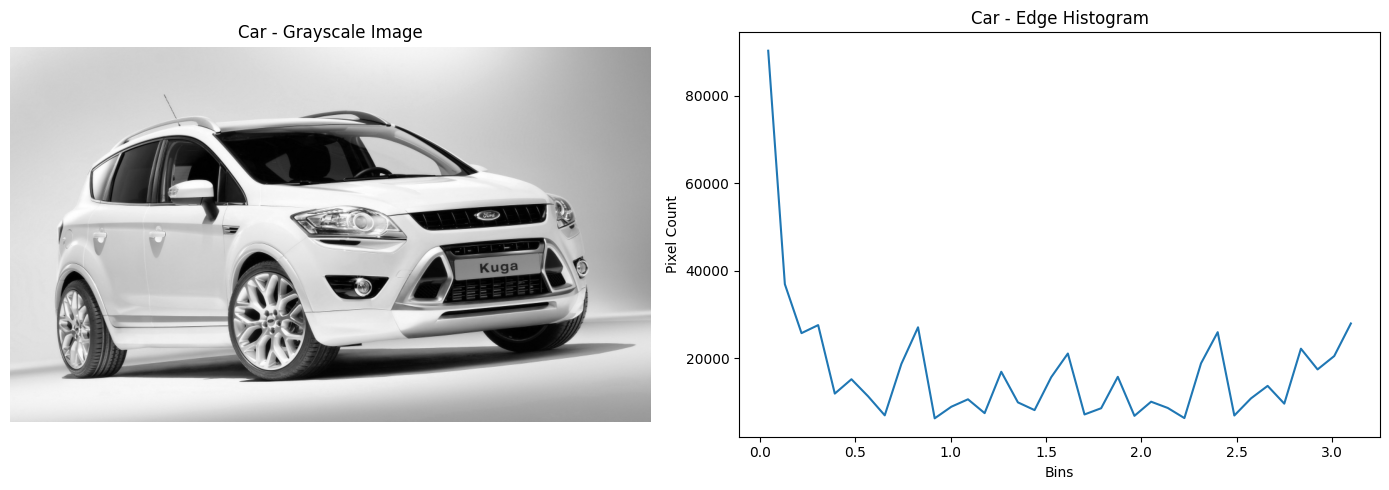

In [21]:
# Create 36-Bin edge histogram for car
hist_car, bins_car = exposure.histogram(angle_car, nbins=36)

# Car image and corresponding edge histogram
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Car Grayscale Image
ax[0].imshow(car_gray, cmap='gray')
ax[0].set_title("Car - Grayscale Image")
ax[0].axis("off")

# Bus edge Histogram
ax[1].plot(bins_car, hist_car)
ax[1].set_xlabel("Bins")
ax[1].set_ylabel("Pixel Count")
ax[1].set_title("Car - Edge Histogram")

plt.tight_layout()
plt.show()

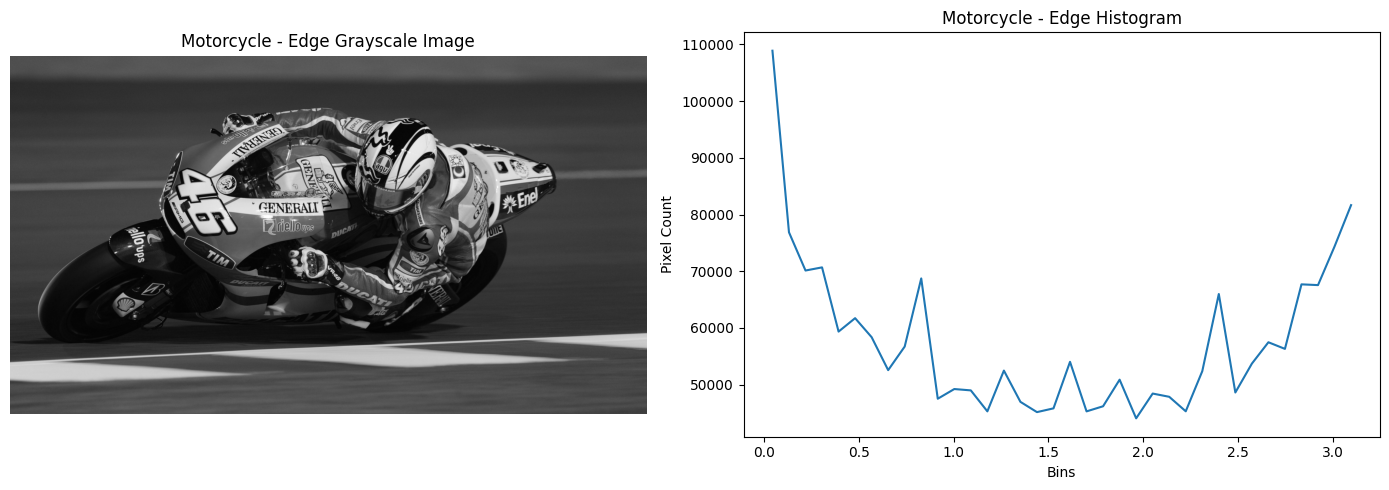

In [22]:
# Create 36-Bin edge histogram for Motorcycle
hist_motorcycle, bins_motorcycle = exposure.histogram(angle_motorcycle, nbins=36)

# Motorcycle image and corresponding edge Histogram
fig, ax = plt.subplots(1, 2, figsize=(14,5))

# Motorcycle grayscale image
ax[0].imshow(motorcycle_gray, cmap='gray')
ax[0].set_title("Motorcycle - Edge Grayscale Image")
ax[0].axis("off")

# Motorcycle edge Histogram
ax[1].plot(bins_motorcycle, hist_motorcycle)
ax[1].set_xlabel("Bins")
ax[1].set_ylabel("Pixel Count")
ax[1].set_title("Motorcycle - Edge Histogram")
plt.tight_layout()
plt.show()

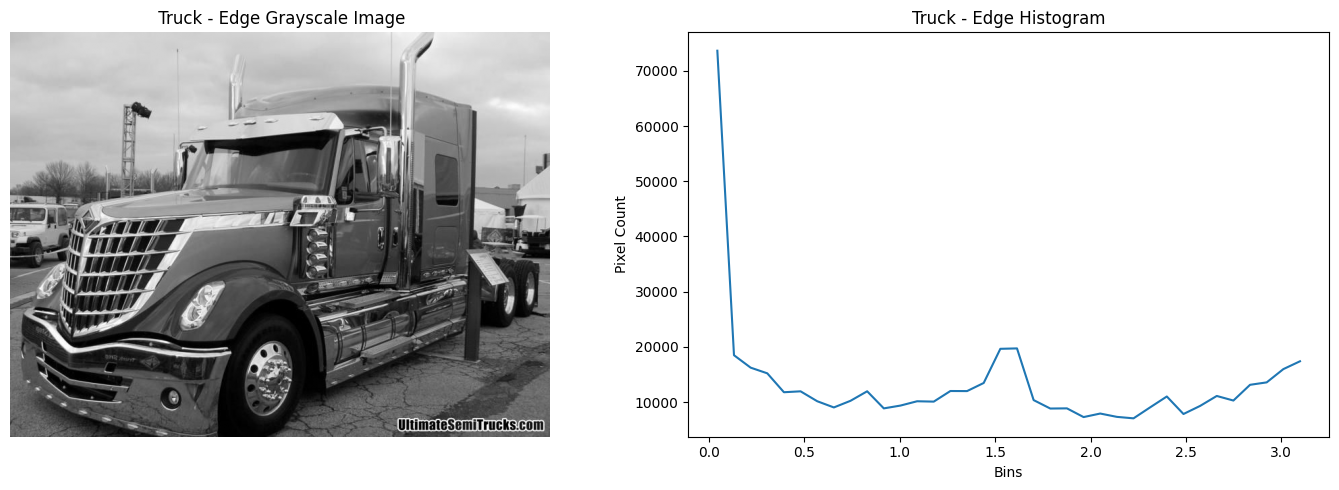

In [23]:
# Create 36-Bin edge histogram for Truck
hist_truck, bins_truck = exposure.histogram(angle_truck, nbins=36)

# Truck image and corresponding edge Histogram
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Truck grayscale image
ax[0].imshow(truck_gray, cmap='gray')
ax[0].set_title(" Truck - Edge Grayscale Image")
ax[0].axis("off")

# Truck edge Histogram
ax[1].plot(bins_truck, hist_truck)
ax[1].set_xlabel("Bins")
ax[1].set_ylabel("Pixel Count")
ax[1].set_title("Truck - Edge Histogram")
plt.tight_layout()
plt.show()

**2(f):** Edge Histogram Comparision Using Distance Metrics

In [24]:
# Compare Car and Truck edge Histograms
from sklearn.metrics import pairwise

distance = pairwise.distance_metrics()['euclidean'](hist_car.reshape(1, -1), hist_truck.reshape(1, -1))

print("Distance between Car and Truck", distance[0][0])

Distance between Car and Truck 43504.2406208866


In [25]:
# Compare Car and Bus edge histograms
distance = pairwise.distance_metrics()['euclidean'](hist_car.reshape(1, -1), hist_bus.reshape(1, -1))

print("Distance Between Car and Bus", distance[0][0])

Distance Between Car and Bus 1570829.9735954874


In [26]:
# Compare Car and Motorcycle edge Histograms
distance = pairwise.distance_metrics()['euclidean'](hist_car.reshape(1, -1), hist_motorcycle.reshape(1, -1))

print("Distance between Car and Motorcycle", distance[0][0])

Distance between Car and Motorcycle 246315.35752364286


The Euclidean distance comparision shows that the car and truck have the simliar edge orientation distributions because they have the smallest distance(43,504.24). While, Car and Motorcycle have the largest distance(246,315.357), indicating the greatest difference in their edge histograms.

In [27]:
# Manhattan Distance Between Car and Truck
distance_manhattan = pairwise.distance_metrics()['manhattan'](hist_car.reshape(1, -1), hist_truck.reshape(1, -1))

print("Manhattan Distance between Car and Truck", distance_manhattan[0][0])

Manhattan Distance between Car and Truck 184504.0


In [28]:
# Cosine Distance between Car and Truck
distance_cosine = pairwise.distance_metrics()['cosine'](hist_car.reshape(1, -1), hist_truck.reshape(1, -1))

print("Cosine Distance between Car and Truck", distance_cosine[0][0])

Cosine Distance between Car and Truck 0.0317778245458471


**Section 3: Histogram of Oriented Gradient(HOG) feature Descriptor**

**3(a):** Compute HOG descriptors and Visualization

In [29]:
# HOG Feature Descriptor for Car
from skimage.feature import hog
hog_features, hog_image = hog(car_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

print("Number of HOG features:", len(hog_features))

Number of HOG features: 338328


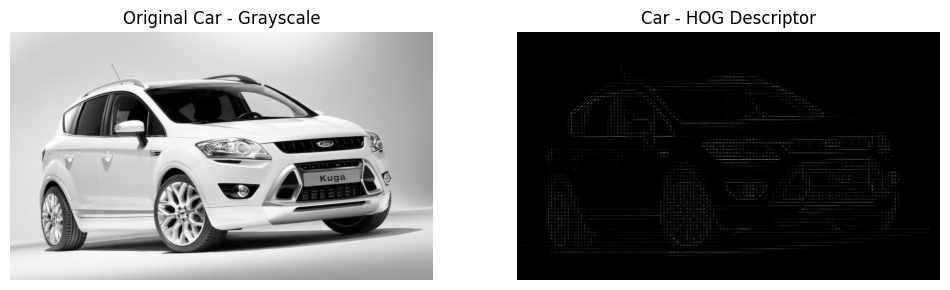

In [33]:
from skimage import exposure

# Make HOG image more visible
hog_visible = exposure.equalize_adapthist(hog_image)

# Display original Car image and HOG image
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(car_gray, cmap='gray')
plt.title("Original Car - Grayscale")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap='gray')
plt.title("Car - HOG Descriptor")
plt.axis('off')

plt.show()


**HOG Analysis**

The HOG descriptor represents the shape and edge orientations of the car. The visualization highlights import structural features such as wheels, windows, vehicle body and other boundaries. The HOG feature vector contains 338,328 features.

**Section 4: Dimensionality Reduction Using PCA**


**4(a):** Images from all four vehicle classes- Bus, Car, Truck, Motorcycle are used for dimensionally reduction using PCA.

**4(b):Convert all images to Edge Histograms**

All images from the four vehicle classes are converted to grayscale. Edge gradient angles are calculated, and each image is converted into 36-bin edge histogram.

In [34]:
# Store edge histograms and class labels
edge_histograms = []
labels = []

In [35]:
# Convert all images into 36-bin histograms
for class_name in classes:
  folder_path = os.path.join(dataset_path, class_name)

  for image_name in os.listdir(folder_path):
    image_path = os.path.join(folder_path, image_name)

    try:
         # Load image
         image = io.imread(image_path)

         # Convert image to grayscale
         gray_image = color.rgb2gray(image)

         # Calculate edge gradient angles
         angles = angle(filters.sobel_h(gray_image), filters.sobel_v(gray_image))

         # Create 36-bin edge histogram
         hist, bins = exposure.histogram(angles, nbins=36)

         # Store histogram and class label
         edge_histograms.append(hist)
         labels.append(class_name)

    except:
      pass

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [36]:
X = np.array(edge_histograms)
labels = np.array(labels)

print("Histogram shape:", X.shape)
print("Number of images:", len(labels))

Histogram shape: (387, 36)
Number of images: 387


**4(c): Principal Component Analysis(PCA)**

In [37]:
from sklearn.decomposition import PCA

# Reduce 36-dimensional edge histograms to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("Original shape:", X.shape)
print("PCA shape:", X_pca.shape)

Original shape: (387, 36)
PCA shape: (387, 2)


**4(d): 2D PCA Visualization**

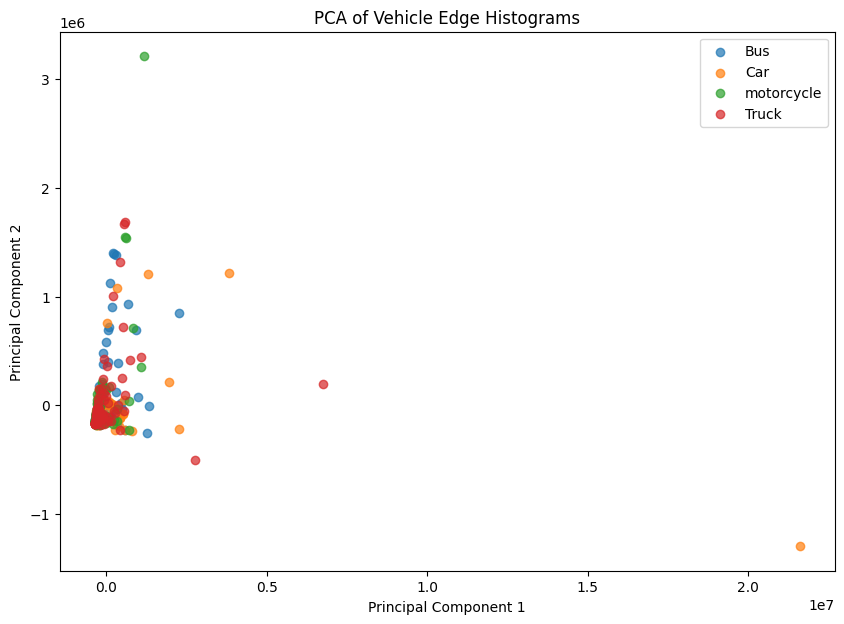

In [38]:
# Plot PCA results for the four vehicle classes
plt.figure(figsize=(10,7))

for class_name in classes:
  mask = labels == class_name
  plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=class_name, alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Vehicle Edge Histograms")
plt.legend()
plt.show()

**PCA Visualization Analysis:** The PCA reduced edge histogram features to two principal components. The four vehicle classes Bus, Truck, Car, Motorcycle show substantial overlap in the 2D PCA plot. Therefore, there are 0 clearly separable classes using these two principal components.

**Part 2: Text Data Processing**

**Section 1: Load and Explore the Text Dataset**

In [39]:
# Load and Explore the text dataset
from google.colab import files
uploaded = files.upload()

Saving train.json to train.json


In [40]:
# Import libraries and review dataset
import pandas as pd

df = pd.read_json('train.json', lines=True)

print("shape:", df.shape)
df.head()

shape: (3000, 13)


,ID,Tweet,anger,anticipation,disgust,fear,joy,love,optimism,pessimism,sadness,surprise,trust
0,2017-En-10973,So I'm not being shady but one of Jongdae's ex...,False,False,False,False,True,False,False,False,False,False,False
1,2017-En-22236,It's about time I start taking my own advice,False,False,False,False,False,False,True,False,False,False,False
2,2017-En-20530,@jk_rowling never thought an angry oompa loomp...,True,True,True,False,False,False,False,False,True,False,False
3,2017-En-10490,Take public opinion on revenge with Pakistan i...,True,False,True,False,False,False,False,False,False,False,False
4,2017-En-11425,the world drives whoever it has assessed as te...,True,True,False,False,False,False,False,False,False,False,False


**Section 2: Token Count Features- CountVectorizer**

In [41]:
# Select tweet text for text processing
tweets = df['Tweet']

# Display the first 5 tweets
tweets.head()


,Tweet
0,So I'm not being shady but one of Jongdae's ex...
1,It's about time I start taking my own advice
2,@jk_rowling never thought an angry oompa loomp...
3,Take public opinion on revenge with Pakistan i...
4,the world drives whoever it has assessed as te...


In [42]:
# Convert tweet text into token counts
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer()
count_features = count_vectorizer.fit_transform(tweets)

# Display the dimensions
count_features.shape


(3000, 9555)

Tweets = 3,000
Token Features = 9,555

**Section 3: TF-IDF Features and TfidfVectorizer**

In [43]:
# TF-IDF
# Convert tweet text into TF-IDF features
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()
tfidf_features = tfidf_vectorizer.fit_transform(tweets)

# Display the dimensions
tfidf_features.shape

(3000, 9555)

**TF-IDF:** 3,000 tweets*9,555 features. So, the dimensionality of two vector representation is 9,555.

**Section 4: Select Four Emotion Classes**

In [44]:
# Display the emotion classes
df.columns

Index(['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy',
       'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
      dtype='object')

In [45]:
# Count tweets in each emotion class
classes = df.columns[2:]
df[classes].sum().sort_values(ascending=False)



,0
disgust,1161
anger,1147
joy,1077
optimism,896
sadness,844
fear,537
anticipation,455
pessimism,339
love,308
trust,172


I have selected four classes: anger, disgust, joy and optimism. I chose these classes for dimensionality reduction and visualizion.

In [46]:
# Select the four emotion classes
selected_classes = ['anger', 'disgust', 'joy', 'optimism']

# Keep tweets that belong to these classes
mask = df[selected_classes].any(axis=1)

df_four = df[mask]

# Check the shape
df_four.shape

(2479, 13)

**Section 5: Dimentionality Reduction to 2D**

In [47]:
# Select token features for the four classes
mask_array = mask.to_numpy()
count_four = count_features[mask_array]

# Reduce dimensions to 2
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
count_2d = pca.fit_transform(count_four.toarray())

# Check Dimensions
count_2d.shape

(2479, 2)

In [48]:
# Select TF-IDF features for the four classes
tfidf_four = tfidf_features[mask_array]

# Reduce dimensions to 2
pca_tfidf = PCA(n_components=2)
tfidf_2d = pca_tfidf.fit_transform(tfidf_four.toarray())

# Check Dimensions
tfidf_2d.shape

(2479, 2)

**Section 6: 2D Plot and Token Count Features**

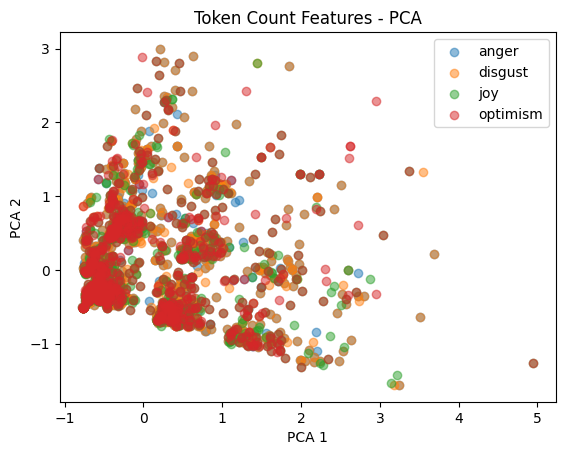

In [49]:
import matplotlib.pyplot as plt

# Plot the four classes using token count features
for emotion in selected_classes:
  rows = df_four[emotion].to_numpy().astype(bool)
  plt.scatter(count_2d[rows,0], count_2d[rows, 1], label=emotion, alpha=0.5)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Token Count Features - PCA")
plt.legend()
plt.show()

Scatter graph shows considerable overlap among the four classes

**Section 7: 2D Plot and TF-IDF Features**

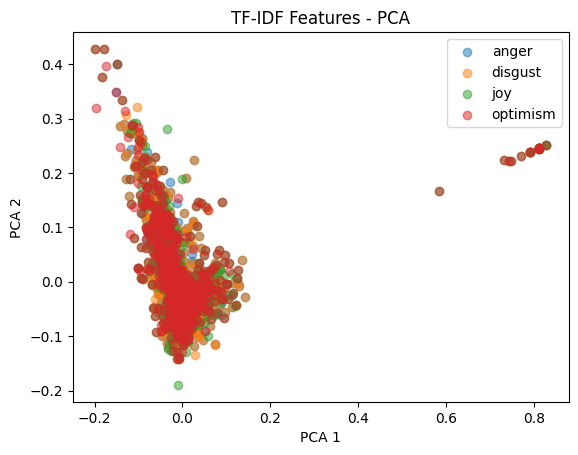

In [50]:
# Plot the four classes using TF-IDF features
for emotion in selected_classes:
  rows = df_four[emotion].to_numpy().astype(bool)
  plt.scatter(tfidf_2d[rows,0], tfidf_2d[rows, 1], label=emotion, alpha=0.5)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("TF-IDF Features - PCA")
plt.legend()
plt.show()


**Section 8: Conclusion**

The four classes are not clearly visually separable in either plot. There is considerable overlap among four classes in both token count and TF-IDF PCA plots.